In [1]:
import pyphysics as phys
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
%matplotlib widget

## 3/2+ state

In [2]:
states = ["12-", "12+", "32-", "32+", "52-", "52+"]
erange = (0.5, 8, 0.025)
elevel = 3.5
wlevel = 50000
angles = [30, 45, 60, 90, 120, 150, 170]

res = defaultdict(list)
for state in states:
    inter = phys.AZUREInterface(f"./inputs/in_{state}.azr")
    for angle in angles:
        inter.set_parameters(
            energy_range=erange,
            angle=angle,
            level_energy=elevel,
            level_width=wlevel,
        )
        inter.call_azure()
        # print(inter.azure.config.labels)
        inter.erase_copy()
        res[state].append(inter.results)

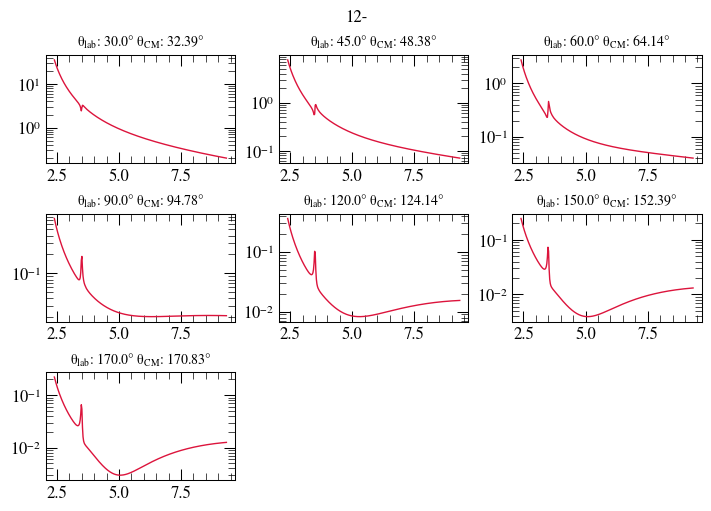

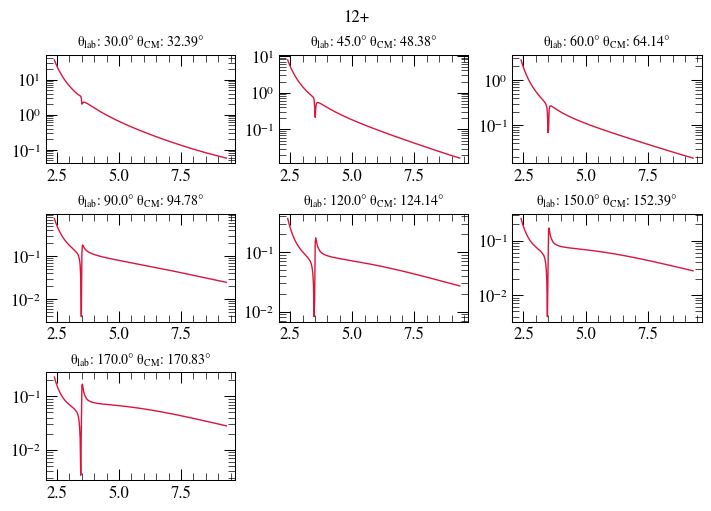

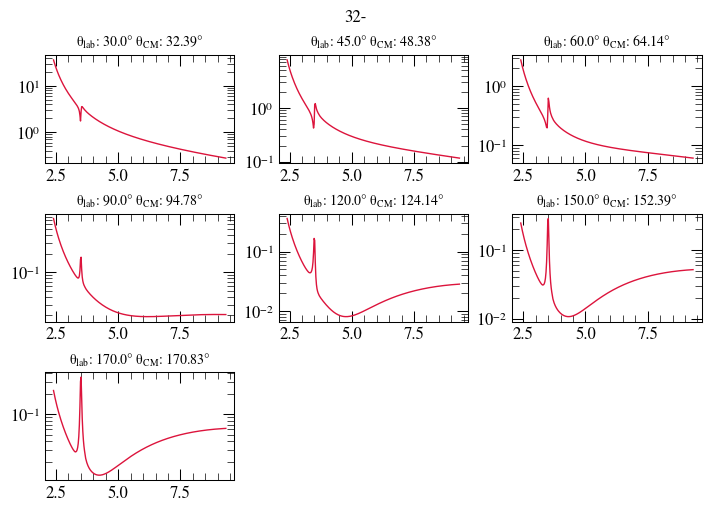

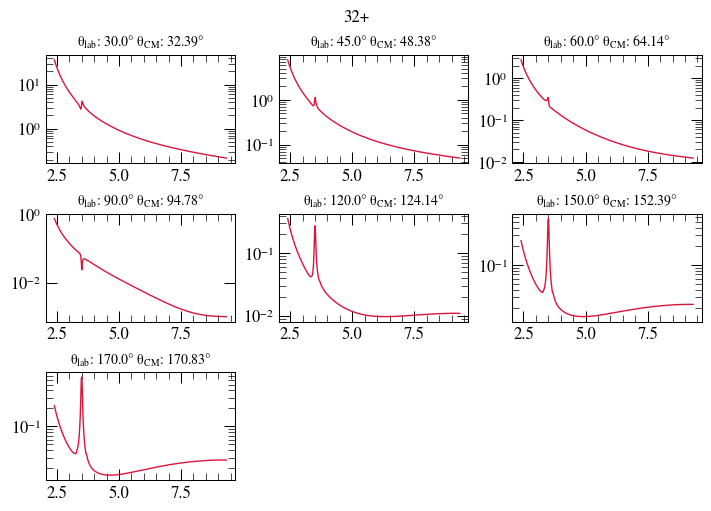

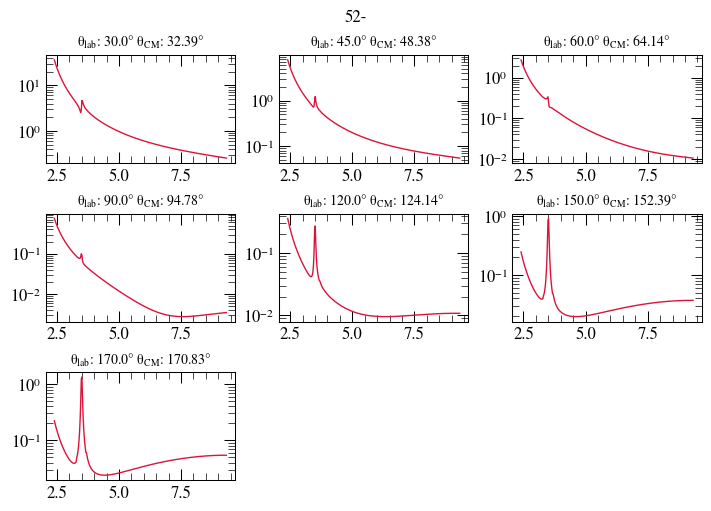

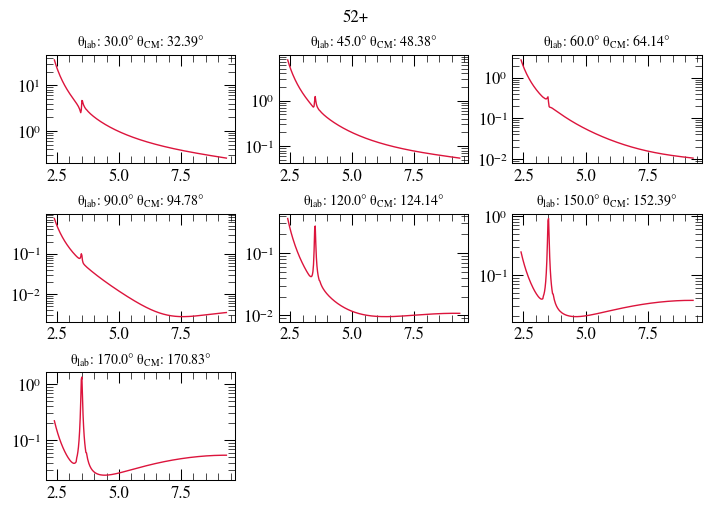

In [3]:
plt.rcParams["xtick.labelsize"] = 12
plt.rcParams["ytick.labelsize"] = 12
# Draw
for state in states:
    fig, axs = plt.subplots(3, 3, constrained_layout=True)
    for i, ax in enumerate(axs.flat):
        if i < len(angles):
            out = res[state][i]
            ax.set_yscale("log")
            ax.plot(out.e_x, out.xs_com_fit, color="crimson")
            lab = rf"$\theta_{{lab}}$: {angles[i]:.1f}°"
            cm = rf"$\theta_{{CM}}$: {out.angle_com[0]:.2f}°"
            ax.set_title(lab + " " + cm, fontsize=10)
            # ax.set_xlabel("Energy (MeV)")
            # ax.set_ylabel("Cross Section")
        else:
            ax.axis("off")

    fig.suptitle(state)

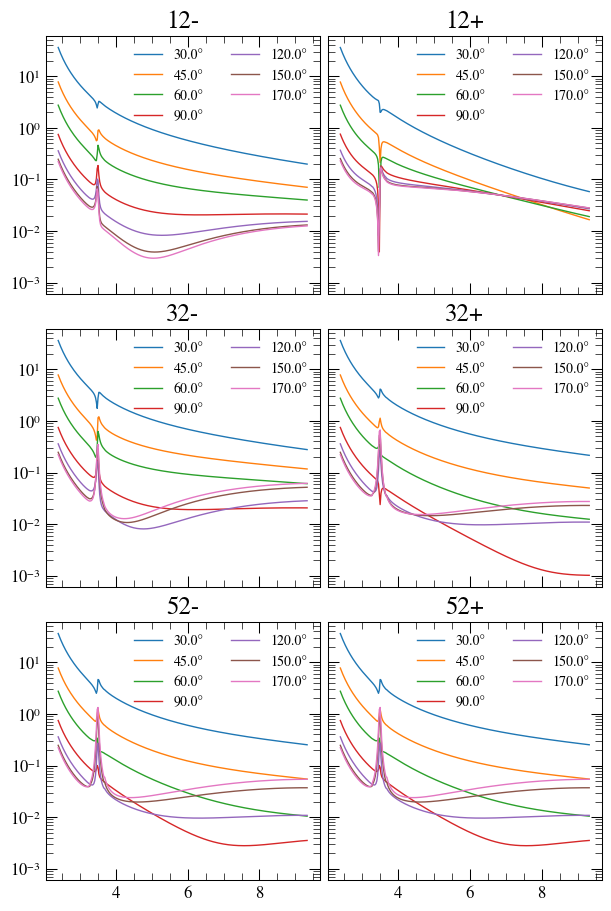

In [4]:
# Draw in single figures
fig, axs = plt.subplots(3, 2, constrained_layout=True, sharex=True, sharey=True, figsize=(6, 9))
for i, state in enumerate(states):
    ax = axs.flat[i]
    for j, angle in enumerate(angles):
        out = res[state][j]
        ax.set_yscale("log")
        ax.plot(out.e_x, out.xs_com_fit, label=f"{angle:.1f}°")
    ax.set_title(state)
    ax.legend(fontsize=10, ncol=2)